# 第17章：完整物理标定项目

**教师参考｜全书深化稿**

## 背景与数据
全部为人工物理情景：90个批次、每批8条、共享批次偏移；不是实验室观测。

## 本次要回答的问题
按批次划分，开发比较基线与模型，冻结后评价18个未见批次。

先写下预判，再运行，最后用实际结果解释；不需要结果符合预期才算成功。

In [1]:
from pathlib import Path
import os, sys
os.environ.setdefault("OMP_NUM_THREADS", "1")
os.environ.setdefault("OPENBLAS_NUM_THREADS", "1")
os.environ.setdefault("MKL_NUM_THREADS", "1")
root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "experiments/common.py").exists()
             and (p / "main.tex").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside the extracted textbook project.")
sys.path.insert(0, str(root / "experiments"))
print("Project:", root)


Project: /mnt/data/book_v3


## 可检查的完整实验代码

下方与对应`experiments`脚本一致。共享的`common.py`只提供固定数据划分、保存表图和绘图设置；模型、目标、参数及比较规则在此明确写出。阅读函数后，再运行下一单元执行实验。

In [2]:
"""Chapter 17: an entirely reproducible, explicitly simulated physical calibration project.
No output is represented as a result from a telescope or laboratory observation.
"""
import numpy as np
import pandas as pd
from sklearn.linear_model import LinearRegression,Ridge
from sklearn.ensemble import RandomForestRegressor
from sklearn.dummy import DummyRegressor
from sklearn.preprocessing import StandardScaler,PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import GroupShuffleSplit,GroupKFold,cross_val_score
from sklearn.metrics import mean_squared_error,mean_absolute_error
from common import *

def run():
    rng=np.random.default_rng(170)
    # 90 measurement sessions. Each session shares a zero-point offset and instrument temperature.
    nrun=90;perrun=8;run_id=np.repeat(np.arange(nrun),perrun)
    temp_run=rng.uniform(15,35,nrun);offset_run=rng.normal(0,.12,nrun)
    x=rng.uniform(0,10,nrun*perrun);T=temp_run[run_id]
    truth=.5+1.8*x+.06*x*x+.02*(T-25)*x
    measured=truth+offset_run[run_id]+rng.normal(0,.08,len(x))
    df=pd.DataFrame({'record_id':np.arange(len(x)),'run_id':run_id,'input_V':x,'temperature_C':T,'output_V':measured})
    df.to_csv(DATA/'simulated_calibration_project.csv',index=False)
    dev,test=next(GroupShuffleSplit(n_splits=1,test_size=.2,random_state=42).split(df,groups=run_id))
    assert not (set(run_id[dev])&set(run_id[test]))
    roles=np.full(len(df),'test',dtype=object);roles[dev]='development';table('ch17_splits',{'record_id':df.record_id,'run_id':run_id,'role':roles})
    X=df[['input_V','temperature_C']];y=df.output_V;cv=list(GroupKFold(5).split(X.iloc[dev],y.iloc[dev],run_id[dev]))
    models={'mean':DummyRegressor(strategy='mean'),'linear':LinearRegression(),
      'quadratic_ridge':make_pipeline(PolynomialFeatures(2,include_bias=False),StandardScaler(),Ridge(alpha=.01)),
      'forest':RandomForestRegressor(n_estimators=200,min_samples_leaf=3,random_state=42,n_jobs=1)}
    rows=[]
    for name,m in models.items():
        s=-cross_val_score(m,X.iloc[dev],y.iloc[dev],cv=cv,scoring='neg_root_mean_squared_error')
        rows.append({'model':name,'CV_RMSE_V':s.mean(),'fold_std_V':s.std()})
    scores=table('ch17_development',rows);show_result(scores)
    selected=scores.sort_values('CV_RMSE_V').iloc[0]['model'];m=models[selected].fit(X.iloc[dev],y.iloc[dev]);pred=m.predict(X.iloc[test])
    errors=pred-y.iloc[test].to_numpy();by=[]
    for group in np.unique(run_id[test]):
        e=errors[run_id[test]==group];by.append({'run_id':int(group),'RMSE_V':np.sqrt(np.mean(e*e)),'mean_error_V':e.mean()})
    table('ch17_test_by_run',by);table('ch17_test_predictions',{'record_id':df.record_id.iloc[test].to_numpy(),'run_id':run_id[test],'target_V':y.iloc[test].to_numpy(),'prediction_V':pred,'residual_V':errors})
    out={'data_status':'synthetic physical teaching project','selected_model':selected,'development_records':len(dev),'test_records':len(test),'development_groups':len(set(run_id[dev])),'test_groups':len(set(run_id[test])),'test_RMSE_V':np.sqrt(np.mean(errors**2)),'test_MAE_V':np.mean(abs(errors))}
    dump('ch17_final',out);print(out)
    plt.figure(figsize=(6.4,4));plt.scatter(y.iloc[test],pred,s=14);a,b=float(y.min()),float(y.max());plt.plot([a,b],[a,b],linestyle='--');plt.xlabel('模拟测量输出（V）');plt.ylabel('最终模型预测（V）');figure('v3_ch17_predictions')

In [3]:
result = run()
if result is not None:
    print(result)

          model  CV_RMSE_V  fold_std_V
           mean   6.759366    0.495449
         linear   0.586874    0.061920
quadratic_ridge   0.143956    0.017020
         forest   0.330718    0.062093
{'data_status': 'synthetic physical teaching project', 'selected_model': 'quadratic_ridge', 'development_records': 576, 'test_records': 144, 'development_groups': 72, 'test_groups': 18, 'test_RMSE_V': np.float64(0.14727685367549978), 'test_MAE_V': np.float64(0.11702221048926623)}


## 检查结果文件与图

下面显示该实验保存的图；所有坐标、样本与数值条件应与正文一致。数据表保存在`results/`。修改代码后，请另存结果或注明变化，不把新配置的输出与正文旧数值混用。

v3_ch17_predictions.png


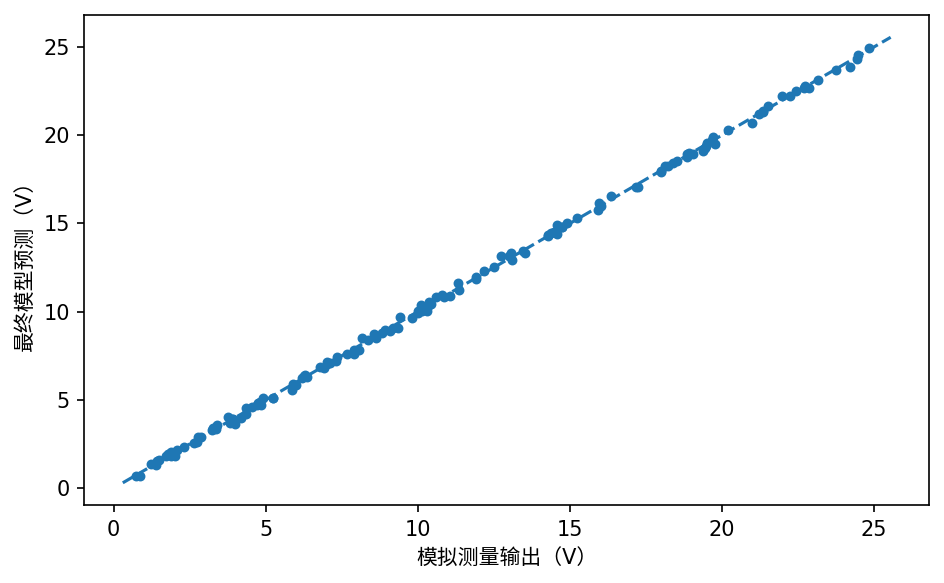

In [4]:
from IPython.display import display, Image
files = sorted((root / "figures").glob("v3_ch17_*.png"))
for path in files:
    print(path.name)
    display(Image(filename=str(path), width=720))
if not files:
    print("This experiment uses tables rather than a new figure.")

## 教师解释与核对

二次模型在该生成机制中占优有明确背景，但不能据此认定真实仪器服从该式。不要将隐藏真值或偏移用于预测。

完整手算解答见`teacher_manual.pdf`。如果结果与这里的参考不同，先检查数据版本、划分、软件环境、目标归一化和随机状态，不要求学生人为调成相同分数。

**评分顺序：**问题与字段角色、数据划分、算法机制、实际结果分析、证据边界。代码能运行但无法说明一项输出的含义，不算完成理解目标。